# E118: on Qwen, does a cheap number already sort the decomposition's verdicts?

## The answer

Mostly yes. Update size and gain each sort every pass and fail of VPD's first table exactly, so its misses are the
smallest updates. Where VPD's readings tell two fine-tunes apart, gain and the steering share tell them apart too,
though partly because each arm is read on its own rows. Where VPD reads reinforcement learning like its null, no cheap
number does better at both steps. The one place VPD's readings agree and the cheap ones do not is the known-facts
fine-tune at its end.


## What we were trying to test

E92 put it this way: a VPD row whose separation a cheap comparator matches says less than its number suggests. E118
read four comparators on every saved Qwen3-1.7B state that already carries a VPD row from E93, E94, E94 Amendment 1,
E104 or E107 Amendment 1. No new fine-tune and no decomposition ran.

- **Update size**: total weight change over the unchanged model's weight norm. Do-nothing reads 0.
- **Gain and rank**: the gain in mean log P of the trained answer, and the unchanged model's rank of its first token.
- **Steering share**: one mean-difference vector added at one block of the unchanged model; its rise in log P over
  the gain.
- **Carrying-neuron share**: the gain of the unchanged model with every MLP neuron's firing taken from the fine-tune's
  MLP inputs, over the fine-tune's gain. E102's reading; it is not bounded by 1.

The VPD rows are E93's pass or fail on the least-squares split, and E94 and E104's outside share, placement and
think overlap. Thirty-two cells are constructed controls, not trained states, and do not apply.

## What we expected

Only controls were filed: the zero update reads nothing, and E92's and E102's control state reproduces. All held
exactly. The cells themselves are a join, with no expected value.


## Does a cheap number sort E93's pass and fail?

**Reading it.** Yes. Every passing state has a larger update and a larger gain than every failing one. The smallest
passing update, the template fine-tune's, is 3.7 parts in ten thousand; the largest failing one is 2.8. The
carrying-neuron share sorts them too, lower on every pass, by 0.01. The closest gain pair, 0.67 against 0.60, is read on different rows; on the shared gold rows the supervised arms
lead by about 1.1 nats. Only size reads no rows. So E93's misses fall exactly on the small
reinforcement-learning, null and own-samples updates.


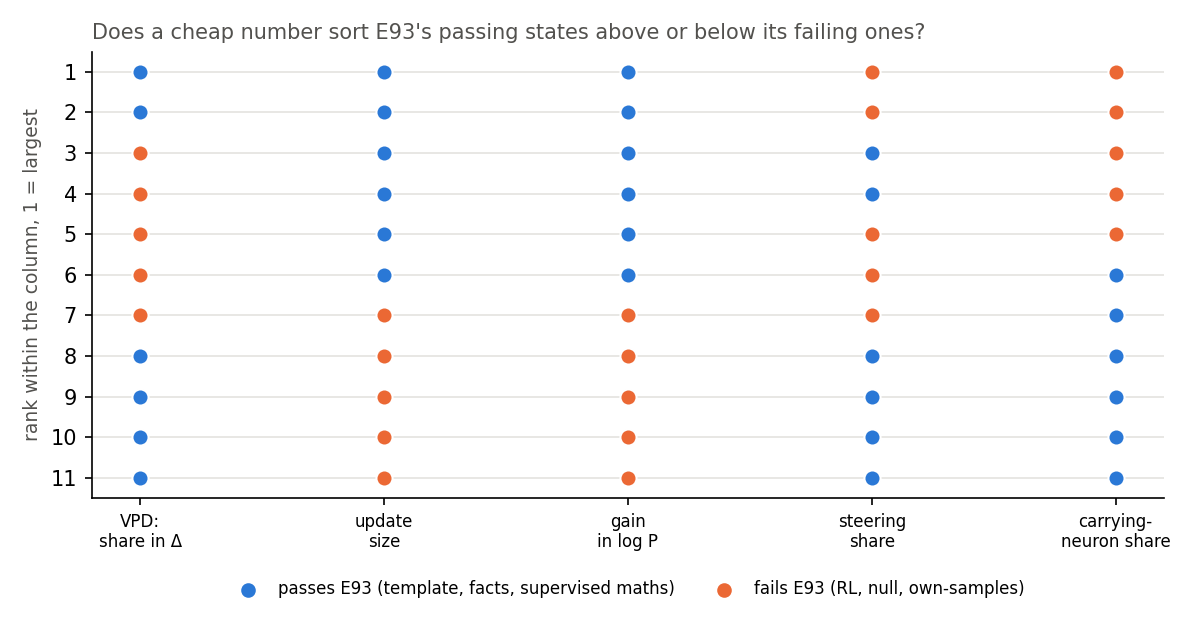

In [1]:
from IPython.display import Image
Image("../experiments/neuron_vpd_table/figures/full_qwen_e93.png")


## Which pairs does each column tell apart?

Each cell is the gap between two arms' seed means over the larger seed spread, E92's stop-rule quantity, applied here
as description; blue means above 1.

**Reading it.** Every pair VPD tells apart, a cheap number tells apart too. On the template against the fictional
facts at matched size, VPD's readings count at 11 to 53 and gain, steering and the carrying share at 82 to 210. Each
anchor is read on its own rows, at both sizes, so part of those gaps is the rows. W0's rank is left out, as it reads only rows. On reinforcement learning against its null, VPD
counts nowhere; update size and steering count at step 10 only, gain at step 100 only.


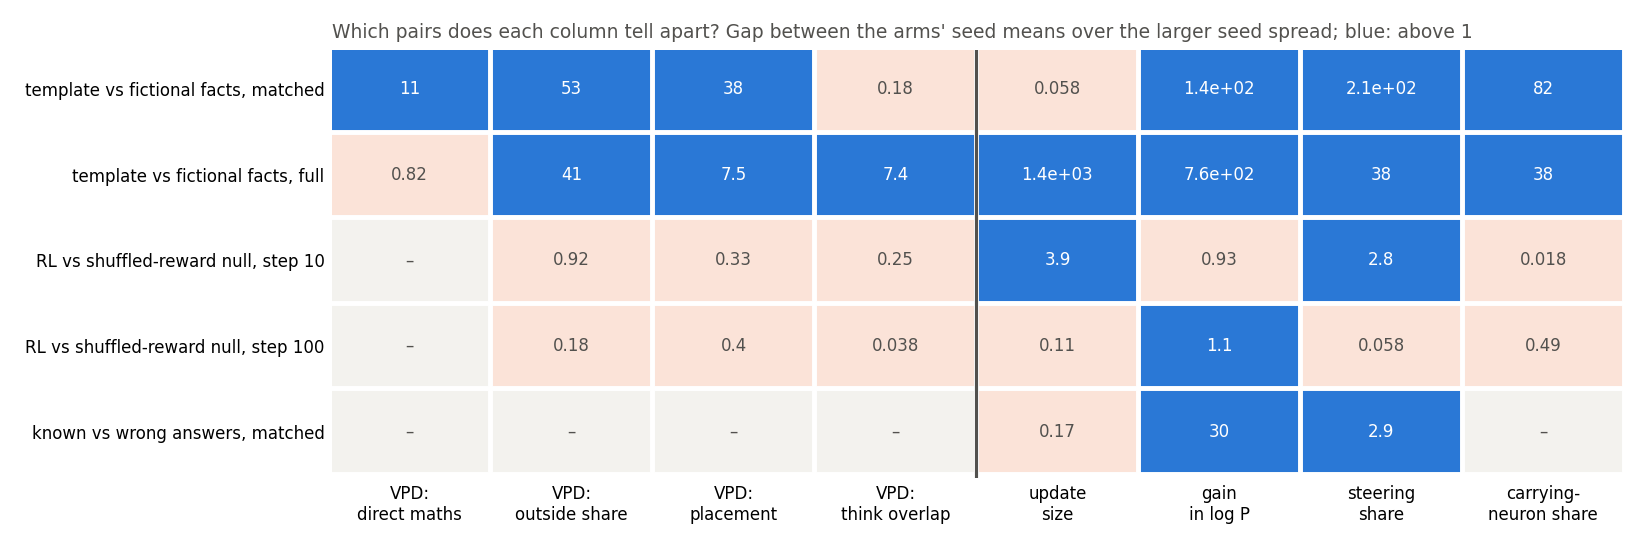

In [2]:
Image("../experiments/neuron_vpd_table/figures/full_qwen_pairs.png")


## Which anchor does the known-facts fine-tune read like?

**Reading it.** At matched size the cheap numbers place it as VPD does; at the end they do not. Zero is the template
fine-tune and 1 the fictional-facts one. At matched size VPD's outside share reads 0.90 and the steering share 0.63.
At the end VPD's outside share and think overlap sit at 0.73 and 0.79, while size and gain read 0.44 and 0.27
and the steering share falls below the template. A place is left out where the known arm's two seeds differ by more
than the anchors' gap: VPD's placement and the carrying share at the end. W0's rank is not shown, as it reads only
rows. Every cheap place compares the known arm's own sentences with the anchors' rows. E94 read this placement as following task and format.


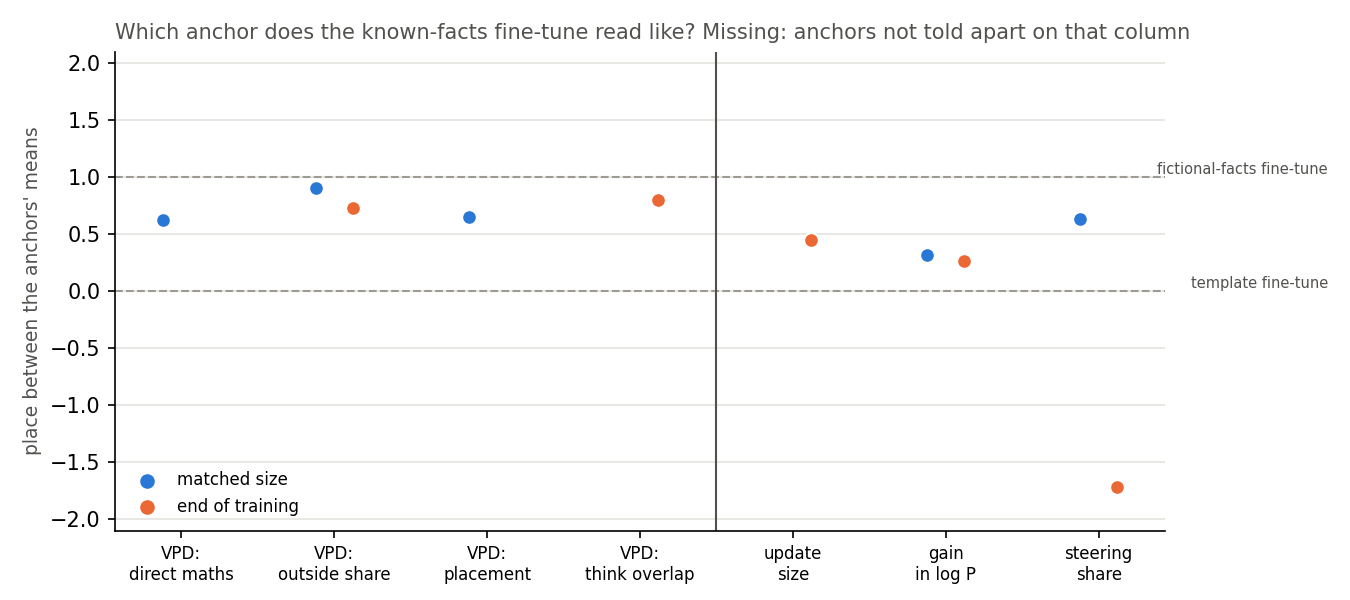

In [3]:
Image("../experiments/neuron_vpd_table/figures/full_qwen_known.png")


## Why the carrying-neuron share can exceed 1

The share is the hybrid model's gain over the fine-tune's gain. The hybrid leaves out the attention change and the
MLP weight change itself, so when those lower log P on net the share exceeds 1. On six maths states it reads 1.03 to
1.07, within the gain's own standard error of 1. On the known-facts end state at seed 42 it reads 2.15: the gain on
the 29 probe rows is only 0.80 ± 0.24, and its seed twin loses 2.34 on the same rows. A ratio whose denominator changes
sign between seeds reads nothing.

## What we learned

On Qwen the decomposition's verdicts are so far matched by update size, gain or steering share on every family but
one. The exception, the known-facts arm at its end, was already read by E94 as task and format. So the case that VPD
reads post-training better than cheap numbers rests, for now, on the 67M.

## How compelling is the evidence

Two seeds per arm. The comparators read different rows per arm while VPD's D3 rows share maths rows, which inflates
the comparators' gaps. The summaries are description, with no filed rule.

## Surprises

The carrying share above 1, explained above.

## What next

Read the comparators on VPD's shared maths rows. If they then stopped telling the anchors apart, VPD's matched-size
separation would stand on its own.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| C0 | the zero update reads nothing | size 0, log P difference 0, empty set | holds |
| C1 | E92's control state reproduces | norm, gain, W0 log P, steering exact | holds |
| C2 | E102's control state reproduces | gain, numerator, set overlap 1.0 | holds |

## Not run

Comparators on the constructed controls; neuron share for the four stored known and wrong matched sets; the rank on
the D3 maths rows; any rule joining a comparator to a VPD reading.

Provenance: `experiments/qwen_comparator_table/results/`, jobs 54382 and 54383, L40 `debug`, $0. The full table:
`experiments/neuron_vpd_table/results/full_table.md`. Report
`reports/analyses/2026-11-06_analysis_e117-e118-neurons-beside-vpd.md`.
